In [6]:
#!pip install xarray parcels copernicusmarine cartopy

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs

/sw/spack-levante/mambaforge-23.1.0-1-Linux-x86_64-3boc6i/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [3]:
import xarray
import parcels
import copernicusmarine

Let's Load the data from Copernicus for our velocity field (here we are using the GLORYS12V1)

In [14]:
vel = copernicusmarine.open_dataset("cmems_mod_glo_phy_my_0.083deg_P1D-m")

INFO - 2026-10-02T11:44:31Z - Selected dataset version: "202311"
INFO - 2026-10-02T11:44:31Z - Selected dataset part: "default"
INFO - 2026-10-02T11:44:32Z - Downloading Copernicus Marine data requires a Copernicus Marine username and password, sign up for free at: https://data.marine.copernicus.eu/register


Copernicus Marine username:

  nkouadio1


Copernicus Marine password:

  ········


In [15]:
vel

<xarray.Dataset>
Dimensions:    (depth: 50, latitude: 2041, longitude: 4320, time: 12227)
Coordinates:
  * depth      (depth) float32 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
  * latitude   (latitude) float32 -80.0 -79.92 -79.83 ... 89.83 89.92 90.0
  * longitude  (longitude) float32 -180.0 -179.9 -179.8 ... 179.8 179.8 179.9
  * time       (time) datetime64[ns] 1993-01-01 1993-01-02 ... 2026-06-23
Data variables:
    bottomT    (time, latitude, longitude) float32 dask.array<chunksize=(1, 512, 2048), meta=np.ndarray>
    mlotst     (time, latitude, longitude) float32 dask.array<chunksize=(1, 512, 2048), meta=np.ndarray>
    siconc     (time, latitude, longitude) float32 dask.array<chunksize=(1, 512, 2048), meta=np.ndarray>
    sithick    (time, latitude, longitude) float32 dask.array<chunksize=(1, 512, 2048), meta=np.ndarray>
    so         (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 512, 2048), meta=np.ndarray>
    thetao     (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 512, 2048), meta=np.ndarray>
    uo         (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 512, 2048), meta=np.ndarray>
    usi        (time, latitude, longitude) float32 dask.array<chunksize=(1, 512, 2048), meta=np.ndarray>
    vo         (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 512, 2048), meta=np.ndarray>
    vsi        (time, latitude, longitude) float32 dask.array<chunksize=(1, 512, 2048), meta=np.ndarray>
    zos        (time, latitude, longitude) float32 dask.array<chunksize=(1, 512, 2048), meta=np.ndarray>
Attributes:
    references:   http://www.mercator-ocean.fr
    source:       MERCATOR GLORYS12V1
    title:        daily mean fields from Global Ocean Physics Analysis and Fo...
    comment:      CMEMS product
    institution:  MERCATOR OCEAN
    history:      2023/06/01 16:20:05 MERCATOR OCEAN Netcdf creation
    Conventions:  CF-1.4

Let's crop on our region of interest

In [2]:
# Let's crop on our region of interest GoG

In [17]:
# Coordinates and variables

min_lat = -23.40
max_lat = 27.04
min_lon = -43.15
max_lon = 21.35
start_year = '2015-01-01T00:00'
end_year = '2016-12-31T00:00'

desired_variables = ['uo', 'vo', 'thetao', 'zos', 'mlotst']

# Subset the dataset
vel_subset = vel[desired_variables].sel(
    time=slice(start_year, end_year),
    latitude=slice(min_lat, max_lat),
    longitude=slice(min_lon, max_lon)
)

# Display the subsetted dataset information
display(vel_subset)

<xarray.Dataset>
Dimensions:    (time: 731, depth: 50, latitude: 605, longitude: 774)
Coordinates:
  * depth      (depth) float32 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
  * latitude   (latitude) float32 -23.33 -23.25 -23.17 ... 26.83 26.92 27.0
  * longitude  (longitude) float32 -43.08 -43.0 -42.92 ... 21.17 21.25 21.33
  * time       (time) datetime64[ns] 2015-01-01 2015-01-02 ... 2016-12-31
Data variables:
    uo         (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 344, 405), meta=np.ndarray>
    vo         (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 344, 405), meta=np.ndarray>
    thetao     (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 344, 405), meta=np.ndarray>
    zos        (time, latitude, longitude) float32 dask.array<chunksize=(1, 344, 405), meta=np.ndarray>
    mlotst     (time, latitude, longitude) float32 dask.array<chunksize=(1, 344, 405), meta=np.ndarray>
Attributes:
    references:   http://www.mercator-ocean.fr
    source:       MERCATOR GLORYS12V1
    title:        daily mean fields from Global Ocean Physics Analysis and Fo...
    comment:      CMEMS product
    institution:  MERCATOR OCEAN
    history:      2023/06/01 16:20:05 MERCATOR OCEAN Netcdf creation
    Conventions:  CF-1.4

Parcels set up

In [36]:
#pip install polars parcels cmocean

In [5]:
from parcels import FieldSet, Field, ParticleSet, Variable, JITParticle

In [8]:
import os
import numpy as np
import xarray as xr

import cmocean

import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
cartopy.config['data_dir'] = os.getenv('CARTOPY_DIR', cartopy.config.get('data_dir'))

from parcels import FieldSet, Field, ParticleSet, Variable, JITParticle
from parcels import AdvectionRK4 
import math
from datetime import timedelta
from operator import attrgetter

from matplotlib import pyplot as plt
#%config InlineBackend.figure_format = 'retina'
plt.ion()  # To trigger the interactive inline mode

 Let's ready the velocity in to parcels

In [21]:
# Initialization (Writes the dataset to the specified NetCDF file)

data_name ='/work/bk1450/b383511/2025_sao_vicente_dispersal/notebooks/exploration/vel_subset.nc'
try:
     os.remove(data_name)
except OSError:
     pass

vel_subset.to_netcdf(path=data_name)

In [38]:
# first output

# 1. Path to your saved local NetCDF file
data_name = '/work/bk1450/b383511/2025_sao_vicente_dispersal/notebooks/exploration/vel_subset2.nc'

# 2. Define filenames, variables, and dimensions for direct loading
filenames = {
    'U': data_name,
    'V': data_name,
    'Temp': data_name,
    'SSH': data_name,
    'MLD': data_name
}

variables = {
    'U': 'uo',
    'V': 'vo',
    'Temp': 'thetao',
    'SSH': 'zos',
    'MLD': 'mlotst'
}

dimensions = {
    'U': {'lon': 'longitude', 'lat': 'latitude', 'depth': 'depth', 'time': 'time'},
    'V': {'lon': 'longitude', 'lat': 'latitude', 'depth': 'depth', 'time': 'time'},
    'Temp': {'lon': 'longitude', 'lat': 'latitude', 'depth': 'depth', 'time': 'time'},
    'SSH': {'lon': 'longitude', 'lat': 'latitude', 'time': 'time'},
    'MLD': {'lon': 'longitude', 'lat': 'latitude', 'time': 'time'}
}

# Build the fieldset directly
fieldset = FieldSet.from_netcdf(filenames, variables, dimensions)

# 3. Define 10 particles safely offshore in the open ocean
n_particles = 10
lons = np.linspace(-20.0, -18.0, n_particles, dtype=np.float32)
lats = np.linspace(10.5, 12.6, n_particles, dtype=np.float32)
depths = np.full(n_particles, 0.5, dtype=np.float32)

pset = ParticleSet(
    fieldset=fieldset,
    pclass=JITParticle,
    lon=lons,
    lat=lats,
    depth=depths
)

# 4. Set up output file
output_file_path = 'CurrentParticles_2years.parquet'
if os.path.exists(output_file_path):
    import shutil
    shutil.rmtree(output_file_path) if os.path.isdir(output_file_path) else os.remove(output_file_path)

output_file = ParticleFile(
    name=output_file_path,
    particleset=pset,
    outputdt=timedelta(days=1)
)

# 5. Define a custom safety kernel to catch and delete particles near the edges
def DeleteOutOfBounds(particle, fieldset, time):
    if (particle.lon < -43.0) or (particle.lon > 21.0) or (particle.lat < -23.0) or (particle.lat > 27.0):
        particle.delete()

# 6. Set up output file
output_file_path = 'CurrentParticles_2years.parquet'
if os.path.exists(output_file_path):
    import shutil
    shutil.rmtree(output_file_path) if os.path.isdir(output_file_path) else os.remove(output_file_path)

output_file = ParticleFile(
    name=output_file_path,
    particleset=pset,
    outputdt=timedelta(days=1)
)

# 7. Execute simulation passing both AdvectionRK4 and the safety kernel in a list
pset.execute(
    [AdvectionRK4, DeleteOutOfBounds],
    runtime=timedelta(days=731),
    dt=timedelta(minutes=30),
    output_file=output_file
)

print("2-year simulation completed successfully!")

 75%|███████▍  | 47089800.0/63158400.0 [24:40<08:25, 31816.47it/s]
 29%|██▉       | 18318600.0/63158400.0 [36:42<1:29:52, 8315.64it/s]
INFO: Output files are stored in CurrentParticles_2years.parquet.zarr.
100%|█████████▉| 62985600.0/63158400.0 [24:37<00:04, 42864.30it/s]

TimeExtrapolationError: U sampled outside time domain at time 2016-12-31T00:00:00.000000000. Try setting allow_time_extrapolation to True.

100%|█████████▉| 62987400.0/63158400.0 [24:47<00:03, 42864.30it/s]

 Experiment with 3 release locations for 2years

In [ ]:
# Initialization (Writes the dataset to the specified NetCDF file)

data_name ='/work/bk1450/b383511/2025_sao_vicente_dispersal/notebooks/exploration/vel_subset.nc'
try:
     os.remove(data_name)
except OSError:
     pass

vel_subset2.to_netcdf(path=data_name)

In [47]:
# second output
# 1. Path to your saved local NetCDF file
data_name = '/work/bk1450/b383511/2025_sao_vicente_dispersal/notebooks/exploration/vel_subset2.nc'

# 2. Define filenames, variables, and dimensions for direct loading
filenames = {
    'U': data_name,
    'V': data_name,
    'Temp': data_name,
    'SSH': data_name,
    'MLD': data_name
}

variables = {
    'U': 'uo',
    'V': 'vo',
    'Temp': 'thetao',
    'SSH': 'zos',
    'MLD': 'mlotst'
}

dimensions = {
    'U': {'lon': 'longitude', 'lat': 'latitude', 'depth': 'depth', 'time': 'time'},
    'V': {'lon': 'longitude', 'lat': 'latitude', 'depth': 'depth', 'time': 'time'},
    'Temp': {'lon': 'longitude', 'lat': 'latitude', 'depth': 'depth', 'time': 'time'},
    'SSH': {'lon': 'longitude', 'lat': 'latitude', 'time': 'time'},
    'MLD': {'lon': 'longitude', 'lat': 'latitude', 'time': 'time'}
}

# Build the fieldset directly
fieldset = FieldSet.from_netcdf(filenames, variables, dimensions)

# Define our 3 exact release centers (Longitude, Latitude)
centers = [
    (-24.5, 16.5),   # Site 1: Cape Verde region
    (-8.86, -2.81),  # Site 2: Equatorial Atlantic
    (-7.2559, 4.469) # Site 3: West African coast (Gulf of Guinea)
]

n_per_loc = 10
lons = []
lats = []

# Generate a small spatial spread around each center point
for center_lon, center_lat in centers:
    cluster_lons = np.linspace(center_lon - 0.2, center_lon + 0.2, n_per_loc, dtype=np.float32)
    cluster_lats = np.linspace(center_lat - 0.2, center_lat + 0.2, n_per_loc, dtype=np.float32)
    
    lons.extend(cluster_lons)
    lats.extend(cluster_lats)

# Convert lists to final numpy arrays
lons = np.array(lons, dtype=np.float32)
lats = np.array(lats, dtype=np.float32)
depths = np.full(len(lons), 0.5, dtype=np.float32)  # Top layer (~0.5m)

# Initialize the combined particle set
pset = ParticleSet(
    fieldset=fieldset,
    pclass=JITParticle,
    lon=lons,
    lat=lats,
    depth=depths
)

# 4. Set up output file
output_file_path = 'CurrentParticles_3Sites_2years.parquet.zarr'
if os.path.exists(output_file_path):
    import shutil
    shutil.rmtree(output_file_path) if os.path.isdir(output_file_path) else os.remove(output_file_path)

output_file = ParticleFile(
    name=output_file_path,
    particleset=pset,
    outputdt=timedelta(days=1)
)

# 5. Define a custom safety kernel to catch and delete particles near the edges
def DeleteOutOfBounds(particle, fieldset, time):
    if (particle.lon < -43.0) or (particle.lon > 21.0) or (particle.lat < -23.0) or (particle.lat > 27.0):
        particle.delete()

# 6. Set up output file
output_file_path = 'CurrentParticles_3Sites_2years.parquet.zarr'
if os.path.exists(output_file_path):
    import shutil
    shutil.rmtree(output_file_path) if os.path.isdir(output_file_path) else os.remove(output_file_path)

output_file = ParticleFile(
    name=output_file_path,
    particleset=pset,
    outputdt=timedelta(days=1)
)

# 7. Execute simulation passing both AdvectionRK4 and the safety kernel in a list
pset.execute(
    [AdvectionRK4, DeleteOutOfBounds],
    runtime=timedelta(days=731),
    dt=timedelta(minutes=30),
    output_file=output_file
)

print(f"Successfully initialized {len(pset)} particles across your 3 chosen regions!")

INFO: Output files are stored in CurrentParticles_3Sites_2years.parquet.zarr.
100%|█████████▉| 62985600.0/63158400.0 [21:51<00:03, 49751.91it/s]

TimeExtrapolationError: U sampled outside time domain at time 2016-12-31T00:00:00.000000000. Try setting allow_time_extrapolation to True.

100%|█████████▉| 62987400.0/63158400.0 [22:02<00:03, 49751.91it/s]

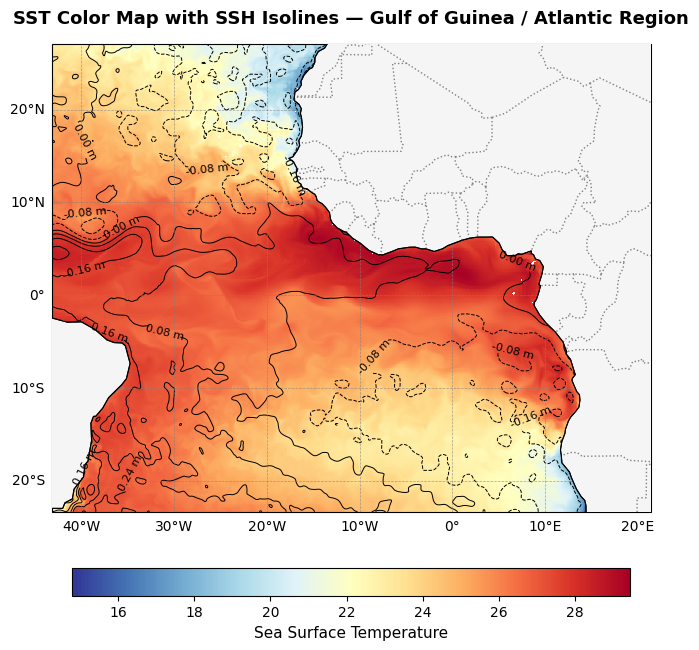

In [31]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1. Take a snapshot of the first time step
ds_snap = vel_subset.isel(time=8)

# Extract SST and select the surface layer (depth/z index 0)
sst = ds_snap['thetao']
if 'depth' in sst.dims:
    sst = sst.isel(depth=0)
elif 'z' in sst.dims:
    sst = sst.isel(z=0)

# Extract SSH and select the surface layer if applicable
ssh = ds_snap['zos']
if 'depth' in ssh.dims:
    ssh = ssh.isel(depth=0)
elif 'z' in ssh.dims:
    ssh = ssh.isel(z=0)

# 2. Set up the map figure with your study region projection
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_extent([-43.15, 21.35, -23.40, 27.04], crs=ccrs.PlateCarree())

# 3. Process and plot Sea Surface Temperature (SST)
if sst.mean().values > 200:
    sst_plot = sst - 273.15
    cbar_label = 'Sea Surface Temperature (°C)'
else:
    sst_plot = sst
    cbar_label = 'Sea Surface Temperature'

im = sst_plot.plot.pcolormesh(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap='RdYlBu_r',
    add_colorbar=False,
    shading='auto',
    zorder=1
)

# Add colorbar for SST
cbar = plt.colorbar(im, orientation='horizontal', pad=0.09, shrink=0.6)
cbar.set_label(cbar_label, fontsize=11)

# 4. Plot Sea Surface Height (SSH) isolines (contours)
contours = ssh.plot.contour(
    ax=ax,
    transform=ccrs.PlateCarree(),
    colors='black',
    linewidths=0.7,
    levels=12,
    add_colorbar=False,
    zorder=2
)
ax.clabel(contours, inline=True, fontsize=8, fmt='%.2f m')

# 5. Add geographical features and boundaries
ax.add_feature(cfeature.LAND, facecolor='#f5f5f5', edgecolor='black', linewidth=0.7, zorder=3)
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor='black', zorder=4)
ax.add_feature(cfeature.BORDERS, linestyle=':', edgecolor='gray', zorder=3)

# 6. Add gridlines with labels
gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.5,
    color='gray',
    alpha=0.7,
    linestyle='--'
)
gl.top_labels = False
gl.right_labels = False

# 7. Titles and layout
plt.title('SST Color Map with SSH Isolines — Gulf of Guinea / Atlantic Region', fontsize=13, fontweight='bold', pad=15)
plt.show()

 Experiment with 3 release locations for 5years

In [11]:
# Coordinates and variables
min_lat = -23.40
max_lat = 27.04
min_lon = -43.15
max_lon = 21.35
start_year = '2020-01-01T00:00'
end_year = '2025-12-31T00:00'

desired_variables = ['uo', 'vo', 'thetao', 'zos', 'mlotst']

# Subset the dataset
vel_subset = vel[desired_variables].sel(
    time=slice(start_year, end_year),
    latitude=slice(min_lat, max_lat),
    longitude=slice(min_lon, max_lon)
)

# Display the subsetted dataset information
display(vel_subset)

<xarray.Dataset>
Dimensions:    (time: 2192, depth: 50, latitude: 605, longitude: 774)
Coordinates:
  * depth      (depth) float32 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
  * latitude   (latitude) float32 -23.33 -23.25 -23.17 ... 26.83 26.92 27.0
  * longitude  (longitude) float32 -43.08 -43.0 -42.92 ... 21.17 21.25 21.33
  * time       (time) datetime64[ns] 2020-01-01 2020-01-02 ... 2025-12-31
Data variables:
    uo         (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 344, 405), meta=np.ndarray>
    vo         (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 344, 405), meta=np.ndarray>
    thetao     (time, depth, latitude, longitude) float32 dask.array<chunksize=(1, 50, 344, 405), meta=np.ndarray>
    zos        (time, latitude, longitude) float32 dask.array<chunksize=(1, 344, 405), meta=np.ndarray>
    mlotst     (time, latitude, longitude) float32 dask.array<chunksize=(1, 344, 405), meta=np.ndarray>
Attributes:
    Conventions:  CF-1.4
    source:       MERCATOR GLORYS12V1
    history:      2023/06/01 16:20:05 MERCATOR OCEAN Netcdf creation
    title:        daily mean fields from Global Ocean Physics Analysis and Fo...
    references:   http://www.mercator-ocean.fr
    comment:      CMEMS product
    institution:  MERCATOR OCEAN

In [ ]:
  # 1. Path to our saved local NetCDF file
data_name = '/work/bk1450/b383511/2025_sao_vicente_dispersal/notebooks/exploration/vel_subset3.nc'

# 2. Define filenames, variables, and dimensions for direct loading
filenames = {
    'U': data_name,
    'V': data_name,
    'Temp': data_name,
    'SSH': data_name,
    'MLD': data_name
}

variables = {
    'U': 'uo',
    'V': 'vo',
    'Temp': 'thetao',
    'SSH': 'zos',
    'MLD': 'mlotst'
}

dimensions = {
    'U': {'lon': 'longitude', 'lat': 'latitude', 'depth': 'depth', 'time': 'time'},
    'V': {'lon': 'longitude', 'lat': 'latitude', 'depth': 'depth', 'time': 'time'},
    'Temp': {'lon': 'longitude', 'lat': 'latitude', 'depth': 'depth', 'time': 'time'},
    'SSH': {'lon': 'longitude', 'lat': 'latitude', 'time': 'time'},
    'MLD': {'lon': 'longitude', 'lat': 'latitude', 'time': 'time'}
}

# Build the fieldset directly
fieldset = FieldSet.from_netcdf(filenames, variables, dimensions)

# Define our 3 exact release centers (Longitude, Latitude)
centers = [
    (-24.5, 16.5),   # Site 1: Cape Verde region
    (-8.86, -2.81),  # Site 2: Equatorial Atlantic
    (-7.2559, 4.469) # Site 3: West African coast (Gulf of Guinea)
]

n_per_loc = 300
lons = []
lats = []

# Generate a small spatial spread around each center point
for center_lon, center_lat in centers:
    cluster_lons = np.linspace(center_lon - 0.2, center_lon + 0.2, n_per_loc, dtype=np.float32)
    cluster_lats = np.linspace(center_lat - 0.2, center_lat + 0.2, n_per_loc, dtype=np.float32)
    
    lons.extend(cluster_lons)
    lats.extend(cluster_lats)

# Convert lists to final numpy arrays
lons = np.array(lons, dtype=np.float32)
lats = np.array(lats, dtype=np.float32)
depths = np.full(len(lons), 0.5, dtype=np.float32)  # Top layer (~0.5m)

# Initialize the combined particle set
pset = ParticleSet(
    fieldset=fieldset,
    pclass=JITParticle,
    lon=lons,
    lat=lats,
    depth=depths
)

# 4. Set up output file
output_file_path = 'CurrentParticles_3Sites_5years.parquet.zarr'
if os.path.exists(output_file_path):
    import shutil
    shutil.rmtree(output_file_path) if os.path.isdir(output_file_path) else os.remove(output_file_path)

output_file = ParticleFile(
    name=output_file_path,
    particleset=pset,
    outputdt=timedelta(days=1)
)

# 5. Define a custom safety kernel to catch and delete out-of-bound particles safely
def DeleteOutOfBounds(particle, fieldset, time):
    if particle.state == StatusCode.ErrorOutOfBounds:
        particle.delete()

# 5. Define a custom safety kernel to catch and delete particles near the edges
#def DeleteOutOfBounds(particle, fieldset, time):
#    if (particle.lon < -43.0) or (particle.lon > 21.0) or (particle.lat < -23.0) or (particle.lat > 27.0):
#        particle.delete()

# 6. Set up output file
output_file_path = 'CurrentParticles_3Sites_5years.parquet.zarr'
if os.path.exists(output_file_path):
    import shutil
    shutil.rmtree(output_file_path) if os.path.isdir(output_file_path) else os.remove(output_file_path)

output_file = ParticleFile(
    name=output_file_path,
    particleset=pset,
    outputdt=timedelta(days=1)
)

# 7. Execute simulation passing both AdvectionRK4 and the safety kernel in a list
pset.execute(
    [AdvectionRK4, DeleteOutOfBounds],
    runtime=timedelta(days=1828),
    dt=timedelta(hours=6),
    output_file=output_file
)

print(f"Successfully initialized {len(pset)} particles across your 3 chosen regions!")

INFO: Output files are stored in CurrentParticles_3Sites_5years.parquet.zarr.
  0%|          | 0/157939200.0 [00:00<?, ?it/s]

In [10]:

# Regional Dispersal Pathways Across the Domain (30-Day Integration)

from datetime import timedelta
import numpy as np
import xarray as xr
from parcels import (
    AdvectionRK4,
    FieldSet,
    JITParticle,
    ParticleSet,
    StatusCode,
)

# 1. Open dataset to get the full spatial coordinates
ds2 = xr.open_dataset('vel_subset2.nc')

# 2. Setup FieldSet
filenames = {'U': 'vel_subset2.nc', 'V': 'vel_subset2.nc'}
variables = {'U': 'uo', 'V': 'vo'}
dimensions = {'lon': 'longitude', 'lat': 'latitude', 'time': 'time'}
fieldset = FieldSet.from_netcdf(filenames, variables, dimensions)

# 3. Create a region-wide grid (subsampling every 15th grid point to keep particle count manageable)
lon_vals = ds2.longitude.values[::15]
lat_vals = ds2.latitude.values[::15]
lon_g, lat_g = np.meshgrid(lon_vals, lat_vals)

lons = lon_g.flatten()
lats = lat_g.flatten()
depths = np.full(lons.shape, 0.5, dtype=np.float32)

# 4. Initialize ParticleSet across the full domain
pset = ParticleSet.from_list(
    fieldset=fieldset,
    pclass=JITParticle,
    lon=lons,
    lat=lats,
    depth=depths,
    time=0,
)


# 5. Define out-of-bounds error handling
def DeleteOutOfBounds(particle, fieldset, time):
  if particle.state == StatusCode.ErrorOutOfBounds:
    particle.delete()


# 6. Run simulation
pset.execute(
    [AdvectionRK4, DeleteOutOfBounds],
    runtime=timedelta(days=30),
    dt=timedelta(hours=1),
    output_file=pset.ParticleFile(
        name='basin_particles.zarr', outputdt=timedelta(days=1)
    ),
)

INFO: Output files are stored in basin_particles.zarr.
100%|██████████| 2592000.0/2592000.0 [00:40<00:00, 63345.45it/s]
